In [1]:
#pip install lime 
# #to install lime I had to use python 3.12 venv and then pip install lime: py -3.12 -m venv .venv && .venv\Scripts\Activate.ps1 && pip install lime


In [1]:
# Import the necessary libraries
import torch
import torch.nn.functional as F
import lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np

c:\Users\Msi\Desktop\thi_co\AI2\Shortcut learning\aai2-shortcut-learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Import the model and the data
import sys
sys.path.insert(0, "..")  # repo root, so that the src. imports work from this folder
from src.models import build_model
from src.data import get_datasets, get_loaders


In [3]:
# Example: CNN model

def select_dataset(p):
    loaders = get_loaders(batch_size=128, p=p)
    train_loader = loaders["train_biased"]
    test_loader  = loaders["test_conflicting"]
    #name = input(print(f"Which dataset would you like to use? (train_biased/test_conflicting)"))
    dataset = get_datasets(p=0.9)["test_conflicting"]
    images, labels, shortcut_labels = next(iter(train_loader))
    return dataset, images, labels, shortcut_labels

def select_model(images):
    model_name = input(print(f"Which model would you like to use? (cnn/mlp)"))
    if model_name == "cnn":
        return build_model("cnn", images)
    elif model_name == "mlp":
        return build_model("mlp", images)
    else:
        raise ValueError(f"Unknown model name: {model_name}")

dataset, images, labels, shortcut_labels = select_dataset(p=0.9)
model = select_model(images)


Which model would you like to use? (cnn/mlp)


ValueError: Unknown model name: 

Here is your selected image:


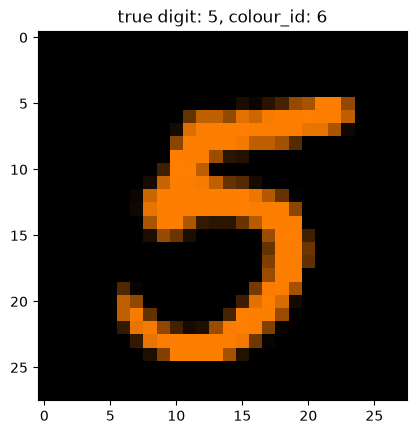

In [22]:
# Selecting one image as an example

def select_random_image(dataset):
    y = np.random.randint(0, len(dataset)-1)
    #print(f"Selected index: {y}, dataset length: {len(dataset)}")
    img, label, colour_id = dataset[y]
    plt.imshow(img.permute(1, 2, 0).numpy())
    print(f"Here is your selected image:")
    plt.title(f"true digit: {label.item()}, colour_id: {colour_id.item()}")
    plt.show()
    return img, label, colour_id

img, label, colour_id = select_random_image(dataset)



In [23]:
# Getting the predicted and the true label for the image
# Ensure that the model is trained and in evaluation mode

def predicted_class(images):
    img = torch.stack([images])  # Stack the images into a batch to move from torch.Size([3, 28, 28]) to torch.Size([1, 3, 28, 28])
    model.eval()
    with torch.no_grad():
        logits = model(img)
        probs = F.softmax(logits, dim=1)
    pred = logits.argmax().item()
    return print(f"predicted {pred}, true {label.item()}")

predicted_class(img)  # Example usage

# print(torch.stack([img]))  # Check the shape of the input tensor
# print(img)


predicted 6, true 5


In [87]:
# Use LIME to explain the model's prediction for the selected image
#print(img.shape) #torch.Size([3, 28, 28])
#print(np.array([img]).shape) #(1, 3, 28, 28)
#print(img.permute(1, 2, 0).numpy().astype("double").shape) #(28, 28, 3)
#print(torch.from_numpy(np.array([img])).float().permute(0, 3, 1, 2).shape) #torch.Size([1, 28, 3, 28])

def predict_fn(batch):                                 # numpy (N, 28, 28, 3)
    t = torch.from_numpy(batch).float().permute(0, 3, 1, 2)   # -> (N, 3, 28, 28)
    with torch.no_grad():
        return F.softmax(model(t), dim=1).numpy() 

def get_explanation(img, predict_fn):
    # img: tensor (3, 28, 28)   
    img_np = img.permute(1, 2, 0).numpy().astype("double")   # (28, 28, 3)
    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        img_np, predict_fn, top_labels=5, hide_color=0, num_samples=1000
    )
    return explanation

  0%|          | 0/1000 [00:00<?, ?it/s]

100%|██████████| 1000/1000 [00:00<00:00, 2024.37it/s]


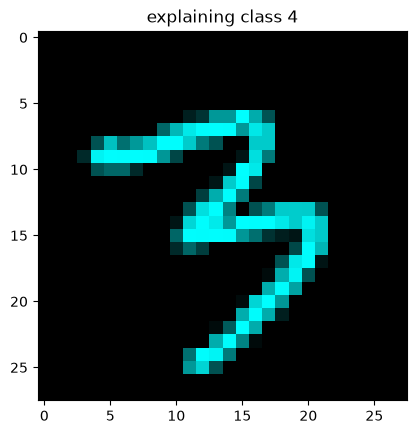

In [88]:
# Visualize the explanation for the top predicted class

def visualize_explanation_lime(explanation):

    top_label = explanation.top_labels[0]
    temp, mask = explanation.get_image_and_mask(
        top_label, positive_only=True, num_features=5, hide_rest=False
    )
    plt.imshow(mark_boundaries(temp, mask))
    plt.title(f"explaining class {top_label}")
    return plt.show()

visualize_explanation_lime(get_explanation(img, predict_fn))

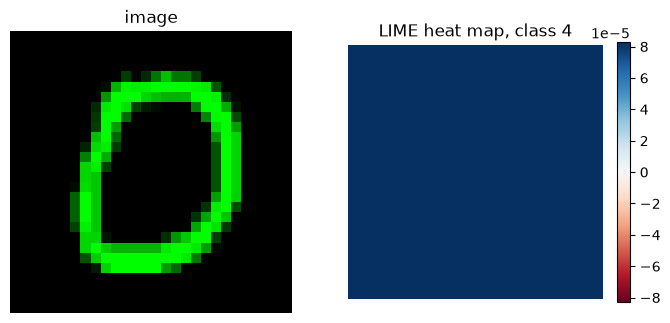

In [89]:
# Use the explanation to create a heatmap for the top predicted class

def get_heatmap_lime(explanation, img):
    label = explanation.top_labels[0]          # or colour_id.item() to explain the colour class

    # superpixel id -> weight for this class
    weights = dict(explanation.local_exp[label])
    segments = explanation.segments            # (28, 28) array of superpixel ids

    heatmap = np.zeros(segments.shape)
    for seg_id, w in weights.items():
        heatmap[segments == seg_id] = w

    m = np.abs(heatmap).max()
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(img_np.astype("float"))
    axes[0].set_title("image")
    im = axes[1].imshow(heatmap, cmap="RdBu", vmin=-m, vmax=m)
    axes[1].set_title(f"LIME heat map, class {label}")
    for ax in axes:
        ax.axis("off")
    fig.colorbar(im, ax=axes[1], fraction=0.046)

    return plt.show()

get_heatmap_lime(explanation, img_np)